Unsupervised learning technique

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

In [2]:
data = pd.read_csv("StudentPerformance.csv")

In [3]:
data["math score"] = pd.to_numeric(data["math score"], errors = "coerce")
data["math score"] = data["math score"].fillna(data["math score"].mean())
data["reading score"] = pd.to_numeric(data["reading score"], errors = "coerce")
data["reading score"] = data["reading score"].fillna(data["reading score"].mean())
data["writing score"] = data["writing score"].fillna(data["writing score"].mean())

In [16]:
x = data[["math score", "reading score", "writing score"]]
# y = data["writing score"]

In [30]:
model = IsolationForest(
    n_estimators=100,
    max_samples=256,
    contamination=0.03, # contamination='auto', Expected proportion of outlier
    random_state=42
)

model.fit(x)

,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",256
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.03
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [39]:
predictions = model.predict(x)

data['Anomaly'] = predictions

print(data['Anomaly'].value_counts())
data.columns

Anomaly
 1    970
-1     30
Name: count, dtype: int64


Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score', 'Anomaly', 'Anomaly_Status'],
      dtype='str')

In [36]:
data['Anomaly_Status'] = data['Anomaly'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

print(data[['math score', 'reading score',
          'writing score', 'Anomaly_Status']].head(10))

    math score  reading score  writing score Anomaly_Status
0         72.0           72.0           74.0         Normal
1         69.0           90.0           88.0         Normal
2         90.0           95.0           93.0         Normal
3         47.0           57.0           44.0         Normal
4         76.0           78.0           75.0         Normal
5         71.0           83.0           78.0         Normal
6         88.0           95.0           92.0         Normal
7         40.0           43.0           39.0         Normal
8         64.0           64.0           67.0         Normal
9         38.0           60.0           50.0         Normal
10        58.0           54.0           52.0         Normal
11        40.0           52.0           43.0         Normal
12        65.0           81.0           73.0         Normal
13        78.0           72.0           70.0         Normal
14        50.0           53.0           58.0         Normal
15        69.0           75.0           

In [46]:
anomalies = data[data["Anomaly_Status"] == "Anomaly"]
# print(anomalies.count())
print(anomalies)

     gender race/ethnicity parental level of education         lunch  \
17   female        group B            some high school  free/reduced   
59   female        group C            some high school  free/reduced   
76     male        group E            some high school      standard   
91     male        group C                 high school  free/reduced   
114  female        group E           bachelor's degree      standard   
145  female        group C                some college  free/reduced   
149    male        group E          associate's degree  free/reduced   
179  female        group D            some high school      standard   
211    male        group C                some college  free/reduced   
327    male        group A                some college  free/reduced   
338  female        group B            some high school  free/reduced   
363  female        group D            some high school  free/reduced   
451  female        group E                some college      stan

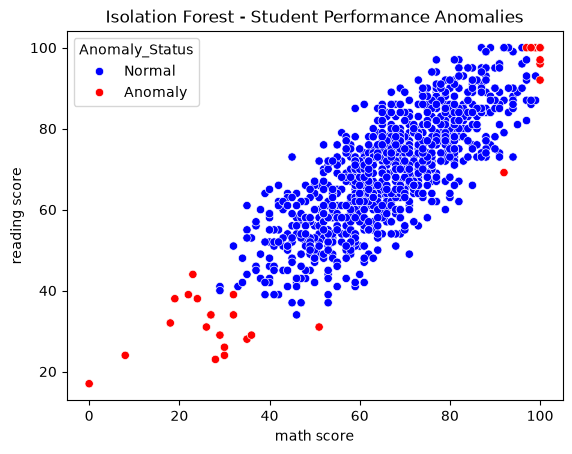

In [33]:
sns.scatterplot(
    data=data,
    x='math score',
    y='reading score',
    hue='Anomaly_Status',
    palette={
        'Normal': 'blue',
        'Anomaly': 'red'
    }
)

plt.title('Isolation Forest - Student Performance Anomalies')
plt.show()